# ДЗ2 — прогнозирование осадков в Оренбурге

Дополнительная версия ДЗ2: исходные baseline, ARIMA и LSTM сохранены; для LSTM добавлены календарные признаки и категории осадков за предыдущие 20 дней. Цель по-прежнему бинарная: будут осадки (1) или нет (0). Оценка — **one-step-ahead forecasting**: на каждом шаге используются только данные, известные до прогнозируемого дня. Разбиение train / validation / test хронологическое.


In [1]:
from pathlib import Path
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay
from sklearn.utils.class_weight import compute_class_weight

SEED = 42
WINDOW = 20
TEST_SHARE = 0.20
VAL_SHARE = 0.20
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)


## Загрузка и подготовка данных

CSV содержит дневные наблюдения Open-Meteo за 2020–2025 годы. Целевой `target` равен 1, если суточная сумма осадков больше 0 мм. Для LSTM добавлены календарные признаки даты и категории осадков: 0 — нет, 1 — небольшие (до 2.5 мм), 2 — средние (до 7.5 мм), 3 — сильные (более 7.5 мм). Пороги заданы в мм/сутки и фиксированы до сравнения моделей.

Источник CSV: [Open-Meteo Historical Weather API](https://archive-api.open-meteo.com/v1/archive), координаты 51.704742° N, 55.081966° E, часовой пояс Europe/Moscow. Сохранённый CSV позволяет повторно запускать ноутбук без сетевого запроса.


In [2]:
DATA_PATH = Path("orenburg_weather_2020_2025.csv")
df = pd.read_csv(DATA_PATH, parse_dates=["date"])
if "precipitation_sum" not in df.columns:
    raise ValueError("В CSV ожидается столбец precipitation_sum (мм).")
df = df[["date", "precipitation_sum"]].dropna().sort_values("date")
if df["date"].duplicated().any():
    raise ValueError("В CSV есть повторяющиеся даты.")
expected_dates = pd.date_range(df.date.min(), df.date.max(), freq="D")
if not df.date.reset_index(drop=True).equals(pd.Series(expected_dates, name="date")):
    raise ValueError("Даты должны идти ежедневно без пропусков.")
df["rain"] = (df["precipitation_sum"] > 0).astype("int8")
print(f"Город: Оренбург; период: {df.date.min().date()} — {df.date.max().date()}")
print(f"Всего наблюдений: {len(df)}; с осадками: {int(df.rain.sum())}; без осадков: {int((df.rain == 0).sum())}")
df.head()


Город: Оренбург; период: 2020-01-01 — 2025-12-31
Всего наблюдений: 2192; с осадками: 972; без осадков: 1220


,date,precipitation_sum,rain
0,2020-01-01,11.5,1
1,2020-01-02,2.2,1
2,2020-01-03,0.0,0
3,2020-01-04,0.0,0
4,2020-01-05,0.0,0


In [3]:
# Календарные признаки и категория осадков на дату наблюдения.
df["timestamp"] = df["date"]
df["precip"] = df["precipitation_sum"]
df["target"] = df["rain"]
df["day"] = df.timestamp.dt.day
df["month"] = df.timestamp.dt.month
df["year"] = df.timestamp.dt.year
df["day_of_week"] = df.timestamp.dt.dayofweek
df["day_of_year"] = df.timestamp.dt.dayofyear
# 0 мм — категория 0; фиксированные границы в мм/сутки.
df["precip_category"] = np.select(
    [df.precip.eq(0), df.precip.le(2.5), df.precip.le(7.5)],
    [0, 1, 2], default=3,
).astype("int8")
for lag in range(1, WINDOW + 1):
    df[f"precip_shift{lag}"] = df["precip_category"].shift(lag)
for lag in range(1, WINDOW + 1):
    assert np.array_equal(df[f"precip_shift{lag}"].iloc[WINDOW:].to_numpy(),
                          df["precip_category"].iloc[WINDOW-lag:-lag].to_numpy())

print("Категории осадков:", df.precip_category.value_counts().sort_index().to_dict())
display(df[["timestamp", "target", "day", "month", "year", "day_of_week", "day_of_year",
            "precip", "precip_category", "precip_shift1", "precip_shift2", "precip_shift20"]].iloc[WINDOW:WINDOW+5])


Категории осадков: {0: 1220, 1: 638, 2: 243, 3: 91}


,timestamp,target,day,month,year,day_of_week,day_of_year,precip,precip_category,precip_shift1,precip_shift2,precip_shift20
20,2020-01-21,1,21,1,2020,1,21,2.0,1,1.0,1.0,3.0
21,2020-01-22,1,22,1,2020,2,22,6.9,2,1.0,1.0,1.0
22,2020-01-23,1,23,1,2020,3,23,2.4,1,2.0,1.0,0.0
23,2020-01-24,1,24,1,2020,4,24,0.8,1,1.0,2.0,0.0
24,2020-01-25,1,25,1,2020,5,25,4.8,2,1.0,1.0,0.0


## Хронологическое разбиение

Последние 20% дней отложены для теста. Предшествующая часть делится на train и validation: validation составляет 20% от development-части. Случайного перемешивания нет.

In [4]:
n = len(df)
test_start = int(n * (1 - TEST_SHARE))
val_start = int(test_start * (1 - VAL_SHARE))
train = df.iloc[:val_start].copy()
validation = df.iloc[val_start:test_start].copy()
test = df.iloc[test_start:].copy()
print(f"train={len(train)}, validation={len(validation)}, test={len(test)}")
assert train.date.max() < validation.date.min() < test.date.min()


train=1402, validation=351, test=439


## Baseline и ARIMA

Baseline всегда выбирает наиболее частый класс в train. ARIMA(2,0,2) обучается только на train. Validation и test оцениваются одинаково: для каждого дня модель прогнозирует один шаг, сохраняет прогноз и только затем получает фактическое значение этого дня для следующего шага. ARIMA даёт числовой прогноз бинарного ряда; для классификации он ограничивается диапазоном [0, 1] и сравнивается с фиксированным порогом 0.5.

In [5]:
y = df["target"].to_numpy(dtype=float)
train_end, val_end = len(train), test_start
baseline_class = int(train.rain.value_counts().idxmax())

# Diagnostic: the earlier notebook used one 351-step forecast for validation.
# Keep it only to show why that incompatible horizon produced a different score.
model_val = ARIMA(y[:train_end], order=(2, 0, 2)).fit()
legacy_val_forecast = np.clip(np.asarray(model_val.forecast(steps=len(validation))), 0, 1)
legacy_val_pred = (legacy_val_forecast >= 0.5).astype(int)
print("Old multi-step validation: positive predictions =", int(legacy_val_pred.sum()),
      "; F1 =", f1_score(y[train_end:val_end], legacy_val_pred, zero_division=0))

# Correct validation: rolling one-step-ahead, exactly like the test evaluation.
val_arima_forecast = []
for actual in y[train_end:val_end]:
    forecast = float(np.asarray(model_val.forecast(steps=1))[0])
    val_arima_forecast.append(float(np.clip(forecast, 0, 1)))
    model_val = model_val.append([actual], refit=False)
val_arima_pred = (np.asarray(val_arima_forecast) >= 0.5).astype(int)
val_actual = y[train_end:val_end].astype(int)
print("Validation actual classes:", dict(zip(*np.unique(val_actual, return_counts=True))))
print("Validation ARIMA predicted classes:", dict(zip(*np.unique(val_arima_pred, return_counts=True))))
print("Validation ARIMA one-step F1:", f1_score(val_actual, val_arima_pred, zero_division=0))

# Test: fit on train + validation, then forecast -> save -> append actual.
arima_result = ARIMA(y[:val_end], order=(2, 0, 2)).fit()
arima_forecast = []
for actual in y[val_end:]:
    forecast = float(np.asarray(arima_result.forecast(steps=1))[0])
    arima_forecast.append(float(np.clip(forecast, 0, 1)))
    arima_result = arima_result.append([actual], refit=False)
arima_forecast = np.asarray(arima_forecast)
arima_pred = (arima_forecast >= 0.5).astype(int)
baseline_pred = np.full(len(test), baseline_class, dtype=int)


Old multi-step validation: positive predictions = 0 ; F1 = 0.0


Validation actual classes: {0: 182, 1: 169}
Validation ARIMA predicted classes: {0: 182, 1: 169}
Validation ARIMA one-step F1: 0.6804733727810651


## LSTM

Однослойная LSTM с 32 нейронами использует предыдущие 20 дней: категориальные лаги осадков и календарные признаки прогнозируемой даты. Выход — вероятность бинарного класса `target`. Параметры обучения и EarlyStopping сохранены из исходного ДЗ2.


In [6]:
def make_sequences(frame, target_start, target_end, window=WINDOW):
    calendar_cols = ["day", "month", "year", "day_of_week", "day_of_year"]
    calendar = frame[calendar_cols].to_numpy(dtype=np.float32)
    # Масштабирование календарных признаков только по train.
    mean = calendar[window:train_end].mean(axis=0)
    std = calendar[window:train_end].std(axis=0)
    std[std == 0] = 1
    calendar = (calendar - mean) / std
    X, y_out = [], []
    for t in range(target_start, target_end):
        history = frame[[f"precip_shift{lag}" for lag in range(window, 0, -1)]].iloc[t].to_numpy(dtype=np.float32)
        known_date = np.repeat(calendar[t][None, :], window, axis=0)
        X.append(np.column_stack([history, known_date]))
        y_out.append(frame["target"].iloc[t])
    return np.asarray(X, dtype=np.float32), np.asarray(y_out, dtype=np.float32)

X_train, y_train = make_sequences(df, WINDOW, train_end)
X_val, y_val = make_sequences(df, train_end, val_end)
X_test, y_test = make_sequences(df, val_end, len(df))
print("Формы:", X_train.shape, X_val.shape, X_test.shape)
assert X_train.shape[1:] == (20, 6) and len(X_test) == len(test)
# Для прогноза t используются категории только t-20,...,t-1.
assert np.array_equal(df["precip_shift1"].iloc[val_end:].to_numpy(),
                      df["precip_category"].iloc[val_end-1:-1].to_numpy())

lstm = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(WINDOW, X_train.shape[2])),
    tf.keras.layers.LSTM(32),
    tf.keras.layers.Dense(1, activation="sigmoid"),
])
lstm.compile(optimizer="adam", loss="binary_crossentropy")
early_stop = tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)
history = lstm.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=30,
                   batch_size=32, callbacks=[early_stop], shuffle=False, verbose=0)
lstm_prob = lstm.predict(X_test, verbose=0).ravel()
lstm_pred = (lstm_prob >= 0.5).astype(int)
print("Фактически выполнено эпох:", len(history.history["loss"]))


Формы: (1382, 20, 6) (351, 20, 6) (439, 20, 6)


Фактически выполнено эпох: 13


## Сравнение моделей и диагностика прогнозов

Положительный класс — наличие осадков (1); для Precision, Recall и F1 используется `zero_division=0`. Persistence предсказывает для дня T фактический класс дня T−1. Все прогнозы сравниваются с одним набором из 439 тестовых целей.

In [7]:
assert len(arima_pred) == len(lstm_pred) == len(baseline_pred) == len(test) == len(lstm_prob)
persistence_pred = y[val_end - 1:-1].astype(int)
assert len(persistence_pred) == len(test)
prediction_check = pd.DataFrame({
    "date": test.date.to_numpy(),
    "actual": y_test.astype(int),
    "previous_day": y[val_end - 1:-1].astype(int),
    "ARIMA_forecast": arima_forecast,
    "LSTM_probability": lstm_prob,
    "ARIMA_pred": arima_pred,
    "LSTM_pred": lstm_pred,
    "Persistence_pred": persistence_pred,
})
assert prediction_check["date"].equals(test["date"].reset_index(drop=True))
assert np.array_equal(prediction_check["actual"], test.rain.to_numpy())
assert np.array_equal(prediction_check["previous_day"], y[val_end - 1:-1].astype(int))
assert prediction_check.notna().all().all()
print("Одинаковые тестовые даты и цели:", len(prediction_check), "из", len(test))
print("Точно совпадают массивы ARIMA и LSTM:", np.array_equal(arima_pred, lstm_pred))
print("Доля попарных совпадений бинарных прогнозов:")
agreement = pd.Series({
    "ARIMA — LSTM": np.mean(arima_pred == lstm_pred),
    "ARIMA — Persistence": np.mean(arima_pred == persistence_pred),
    "LSTM — Persistence": np.mean(lstm_pred == persistence_pred),
}, name="Доля совпадений")
display(agreement.to_frame().T)
print("Диагностика первых 10 тестовых дней:")
display(prediction_check.head(10).round(4))

def metrics(name, pred):
    return {
        "Модель": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, pos_label=1, zero_division=0),
        "Recall": recall_score(y_test, pred, pos_label=1, zero_division=0),
        "F1-score": f1_score(y_test, pred, pos_label=1, zero_division=0),
    }
results = pd.DataFrame([
    metrics("Baseline", baseline_pred),
    metrics("Persistence", persistence_pred),
    metrics("ARIMA", arima_pred),
    metrics("LSTM", lstm_pred),
]).set_index("Модель")
results.round(4)


Одинаковые тестовые даты и цели: 439 из 439
Точно совпадают массивы ARIMA и LSTM: False
Доля попарных совпадений бинарных прогнозов:


,ARIMA — LSTM,ARIMA — Persistence,LSTM — Persistence
Доля совпадений,0.615034,1.0,0.615034


Диагностика первых 10 тестовых дней:


,date,actual,previous_day,ARIMA_forecast,LSTM_probability,ARIMA_pred,LSTM_pred,Persistence_pred
0,2024-10-19,1,0,0.1984,0.3824,0,0,0
1,2024-10-20,1,1,0.5668,0.5184,1,1,1
2,2024-10-21,0,1,0.5851,0.4897,1,0,1
3,2024-10-22,0,0,0.3037,0.3957,0,0,0
4,2024-10-23,1,0,0.3060,0.3928,0,0,0
5,2024-10-24,1,1,0.6115,0.5203,1,1,1
6,2024-10-25,1,1,0.6186,0.6119,1,1,1
7,2024-10-26,1,1,0.6906,0.7604,1,1,1
8,2024-10-27,1,1,0.7063,0.7588,1,1,1
9,2024-10-28,0,1,0.7259,0.5510,1,1,1


,Accuracy,Precision,Recall,F1-score
Модель,,,,
Baseline,0.5216,0.0000,0.0000,0.0000
Persistence,0.6697,0.6555,0.6524,0.6539
ARIMA,0.6697,0.6555,0.6524,0.6539
LSTM,0.5626,0.6216,0.2190,0.3239


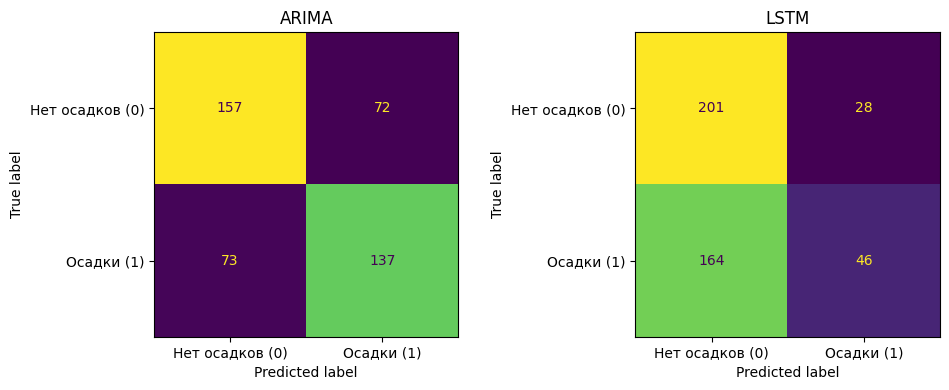

Baseline: предсказания классов {0: 439}
Persistence: предсказания классов {0: 230, 1: 209}
ARIMA: предсказания классов {0: 230, 1: 209}
LSTM: предсказания классов {0: 365, 1: 74}
Порог классификации для ARIMA и LSTM: 0.5
ARIMA: forecast(steps=1) перед append([actual]); LSTM: predict(X_test), вход содержит категории t−20…t−1 и календарь даты t.
Превышение baseline по Accuracy/F1:
             Accuracy  F1-score
Модель                         
Persistence      True      True
ARIMA            True      True
LSTM             True      True


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, name, pred in [(axes[0], "ARIMA", arima_pred), (axes[1], "LSTM", lstm_pred)]:
    ConfusionMatrixDisplay(confusion_matrix(y_test, pred, labels=[0, 1]),
                           display_labels=["Нет осадков (0)", "Осадки (1)"]).plot(ax=ax, colorbar=False)
    ax.set_title(name)
plt.tight_layout()
plt.show()

for name, pred in [("Baseline", baseline_pred), ("Persistence", persistence_pred), ("ARIMA", arima_pred), ("LSTM", lstm_pred)]:
    print(f"{name}: предсказания классов {dict(zip(*np.unique(pred, return_counts=True)))}")
print("Порог классификации для ARIMA и LSTM: 0.5")
print("ARIMA: forecast(steps=1) перед append([actual]); LSTM: predict(X_test), вход содержит категории t−20…t−1 и календарь даты t.")
print("Превышение baseline по Accuracy/F1:")
print(results.loc[["Persistence", "ARIMA", "LSTM"], ["Accuracy", "F1-score"]].gt(results.loc["Baseline", ["Accuracy", "F1-score"]]))


## Итоговый вывод

Вывод ниже формируется из реальных результатов, включая persistence baseline. Если ARIMA и LSTM дают одинаковые предсказания, сравнение с persistence показывает, сводится ли это к сохранению класса предыдущего дня.

In [9]:
print(f"В работе использованы данные Оренбурга за {df.date.min():%d.%m.%Y}–{df.date.max():%d.%m.%Y}: {int(df.rain.sum())} дней с осадками и {int((df.rain == 0).sum())} дней без осадков.")
print(f"Сравнивались baseline, persistence, ARIMA(2,0,2) и LSTM (20 дней, календарные признаки, категории осадков, 32 нейрона); LSTM обучена {len(history.history['loss'])} эпох.")
print(f"ARIMA: Accuracy={results.loc['ARIMA','Accuracy']:.3f}, F1={results.loc['ARIMA','F1-score']:.3f}; LSTM: Accuracy={results.loc['LSTM','Accuracy']:.3f}, F1={results.loc['LSTM','F1-score']:.3f}; persistence: Accuracy={results.loc['Persistence','Accuracy']:.3f}, F1={results.loc['Persistence','F1-score']:.3f}.")
if np.array_equal(arima_pred, lstm_pred) and np.array_equal(arima_pred, persistence_pred):
    print("ARIMA и LSTM полностью совпали с persistence: на этой выборке их бинарные решения эквивалентны прогнозу класса предыдущего дня.")
elif np.array_equal(arima_pred, lstm_pred):
    print("ARIMA и LSTM полностью совпали друг с другом, но отличаются от persistence хотя бы на части дат.")
else:
    print("ARIMA и LSTM различаются по бинарным прогнозам.")
print(f"На validation у ARIMA классы: {dict(zip(*np.unique(val_actual, return_counts=True)))}; положительных прогнозов: {int(val_arima_pred.sum())}; F1={f1_score(val_actual, val_arima_pred, zero_division=0):.3f}.")
print("Оценка validation теперь тоже one-step-ahead; ограничения: один город и период, бинаризация осадков при пороге 0 мм и фиксированные параметры моделей.")


В работе использованы данные Оренбурга за 01.01.2020–31.12.2025: 972 дней с осадками и 1220 дней без осадков.
Сравнивались baseline, persistence, ARIMA(2,0,2) и LSTM (20 дней, календарные признаки, категории осадков, 32 нейрона); LSTM обучена 13 эпох.
ARIMA: Accuracy=0.670, F1=0.654; LSTM: Accuracy=0.563, F1=0.324; persistence: Accuracy=0.670, F1=0.654.
ARIMA и LSTM различаются по бинарным прогнозам.
На validation у ARIMA классы: {0: 182, 1: 169}; положительных прогнозов: 169; F1=0.680.
Оценка validation теперь тоже one-step-ahead; ограничения: один город и период, бинаризация осадков при пороге 0 мм и фиксированные параметры моделей.
